In [1]:
import os
import sys
import platform
import subprocess
import psutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")

os.makedirs("data", exist_ok=True)
os.makedirs("figures", exist_ok=True)

env_info = {
    "OS": f"{platform.system()} {platform.release()}",
    "Processor": platform.processor(),
    "Physical_Cores": psutil.cpu_count(logical=False),
    "Logical_Processors": psutil.cpu_count(logical=True),
    "RAM_GB": round(psutil.virtual_memory().total / (1024**3), 2),
    "Python_Version": platform.python_version(),
    "NumPy_Version": np.__version__,
    "Pandas_Version": pd.__version__
}
pd.DataFrame([env_info])

,OS,Processor,Physical_Cores,Logical_Processors,RAM_GB,Python_Version,NumPy_Version,Pandas_Version
0,Windows 11,"Intel64 Family 6 Model 170 Stepping 4, Genuine...",16,22,15.37,3.14.6,2.4.6,3.0.3


In [2]:
def generate_ref_dense(n, seed):
    mat = np.zeros((n, n), dtype=np.float64)
    state = seed & 0xFFFFFFFFFFFFFFFF
    for i in range(n):
        for j in range(n):
            state = (state * 6364136223846793005 + 1442695040888963407) & 0xFFFFFFFFFFFFFFFF
            mat[i, j] = (state >> 11) * (1.0 / 9007199254740992.0)
    return mat

def generate_ref_sparse(n, density, seed):
    mat = np.zeros((n, n), dtype=np.float64)
    state = seed & 0xFFFFFFFFFFFFFFFF
    for i in range(n):
        for j in range(n):
            state = (state * 6364136223846793005 + 1442695040888963407) & 0xFFFFFFFFFFFFFFFF
            prob = (state >> 11) * (1.0 / 9007199254740992.0)
            if prob < density:
                state = (state * 6364136223846793005 + 1442695040888963407) & 0xFFFFFFFFFFFFFFFF
                val = (state >> 11) * (1.0 / 9007199254740992.0)
                if val == 0.0:
                    val = 1.0
                mat[i, j] = val
    return mat

n_val = 20
seed_val = 42
rtol = 1e-12
atol = 1e-12

methods_to_validate = [
    ("Dense_Baseline_ijk", 1.0),
    ("Dense_LoopReorder_ikj", 1.0),
    ("Dense_Strassen", 1.0),
    ("Sparse_CSR", 1.0),
    ("Sparse_CSR", 0.1)
]

val_rows = []
for method, dens in methods_to_validate:
    if dens >= 1.0:
        A_ref = generate_ref_dense(n_val, seed_val)
        B_ref = generate_ref_dense(n_val, seed_val + 1)
    else:
        A_ref = generate_ref_sparse(n_val, dens, seed_val)
        B_ref = generate_ref_sparse(n_val, dens, seed_val + 1)
    C_ref = np.matmul(A_ref, B_ref)

    cmd = [sys.executable, "src/matmul_a2.py", "dump", method, str(n_val), str(dens), "0", "1", str(seed_val)]
    out = subprocess.check_output(cmd).decode().strip().split(",")
    C_out = np.array([float(x) for x in out], dtype=np.float64).reshape((n_val, n_val))
    max_err = float(np.max(np.abs(C_out - C_ref)))
    passed = bool(np.allclose(C_out, C_ref, rtol=rtol, atol=atol))
    val_rows.append({
        "Method": method,
        "N": n_val,
        "Density": dens,
        "Max_Abs_Error": max_err,
        "Passed_AllClose": passed
    })

pd.DataFrame(val_rows)

,Method,N,Density,Max_Abs_Error,Passed_AllClose
0,Dense_Baseline_ijk,20,1.0,2.664535e-15,True
1,Dense_LoopReorder_ikj,20,1.0,2.664535e-15,True
2,Dense_Strassen,20,1.0,2.664535e-15,True
3,Sparse_CSR,20,1.0,2.664535e-15,True
4,Sparse_CSR,20,0.1,1.110223e-16,True


In [3]:
dense_methods = ["Dense_Baseline_ijk", "Dense_LoopReorder_ikj", "Dense_Strassen"]
dense_sizes = [64, 128, 256, 384, 512]
warmup_runs = 1
measured_reps = 5
seed_bench = 12345
max_runtime_budget_s = 150.0

part_a_raw = []
part_a_status = []

for method in dense_methods:
    timed_out = False
    for n in dense_sizes:
        if timed_out:
            part_a_status.append({"Part": "A", "Method": method, "N": n, "Density": 1.0, "Status": "SKIPPED_AFTER_TIMEOUT"})
            continue
        cmd = [sys.executable, "src/matmul_a2.py", "benchmark", method, str(n), "1.0", str(warmup_runs), str(measured_reps), str(seed_bench)]
        try:
            proc = subprocess.run(cmd, capture_output=True, text=True, timeout=max_runtime_budget_s, check=True)
            for line in proc.stdout.splitlines():
                if not line.strip():
                    continue
                p = line.strip().split(",")
                part_a_raw.append({
                    "part": "PartA_Dense",
                    "method": p[0],
                    "representation": p[1],
                    "n": int(p[2]),
                    "numeric_type": p[3],
                    "density": float(p[4]),
                    "sparsity": float(p[5]),
                    "repetition": int(p[6]),
                    "kernel_time_s": float(p[7]),
                    "conversion_time_s": float(p[8]),
                    "total_time_s": float(p[9]),
                    "memory_kb": float(p[10]),
                    "nnz_a": int(p[11]),
                    "nnz_b": int(p[12]),
                    "nnz_c": int(p[13]),
                    "checksum": float(p[14]),
                    "threads": int(p[15])
                })
            part_a_status.append({"Part": "A", "Method": method, "N": n, "Density": 1.0, "Status": "COMPLETED"})
        except subprocess.TimeoutExpired:
            part_a_status.append({"Part": "A", "Method": method, "N": n, "Density": 1.0, "Status": f"TIMEOUT_{max_runtime_budget_s}S"})
            timed_out = True

df_raw_a = pd.DataFrame(part_a_raw)
df_raw_a.to_csv("data/raw_part_a_dense.csv", index=False)
pd.DataFrame(part_a_status)

,Part,Method,N,Density,Status
0,A,Dense_Baseline_ijk,64,1.0,COMPLETED
1,A,Dense_Baseline_ijk,128,1.0,COMPLETED
2,A,Dense_Baseline_ijk,256,1.0,COMPLETED
3,A,Dense_Baseline_ijk,384,1.0,COMPLETED
4,A,Dense_Baseline_ijk,512,1.0,COMPLETED
5,A,Dense_LoopReorder_ikj,64,1.0,COMPLETED
6,A,Dense_LoopReorder_ikj,128,1.0,COMPLETED
7,A,Dense_LoopReorder_ikj,256,1.0,COMPLETED
8,A,Dense_LoopReorder_ikj,384,1.0,COMPLETED
9,A,Dense_LoopReorder_ikj,512,1.0,COMPLETED


In [4]:
sparse_compare_methods = ["Dense_Baseline_ijk", "Dense_LoopReorder_ikj", "Sparse_CSR"]
sparse_sizes = [200, 400]
densities = [0.01, 0.05, 0.10, 0.25, 0.50]

part_b_raw = []
part_b_status = []

for n in sparse_sizes:
    for dens in densities:
        for method in sparse_compare_methods:
            cmd = [sys.executable, "src/matmul_a2.py", "benchmark", method, str(n), str(dens), str(warmup_runs), str(measured_reps), str(seed_bench)]
            try:
                proc = subprocess.run(cmd, capture_output=True, text=True, timeout=max_runtime_budget_s, check=True)
                for line in proc.stdout.splitlines():
                    if not line.strip():
                        continue
                    p = line.strip().split(",")
                    part_b_raw.append({
                        "part": "PartB_Sparse",
                        "method": p[0],
                        "representation": p[1],
                        "n": int(p[2]),
                        "numeric_type": p[3],
                        "density": float(p[4]),
                        "sparsity": float(p[5]),
                        "repetition": int(p[6]),
                        "kernel_time_s": float(p[7]),
                        "conversion_time_s": float(p[8]),
                        "total_time_s": float(p[9]),
                        "memory_kb": float(p[10]),
                        "nnz_a": int(p[11]),
                        "nnz_b": int(p[12]),
                        "nnz_c": int(p[13]),
                        "checksum": float(p[14]),
                        "threads": int(p[15])
                    })
                part_b_status.append({"Part": "B", "Method": method, "N": n, "Density": dens, "Status": "COMPLETED"})
            except subprocess.TimeoutExpired:
                part_b_status.append({"Part": "B", "Method": method, "N": n, "Density": dens, "Status": f"TIMEOUT_{max_runtime_budget_s}S"})

df_raw_b = pd.DataFrame(part_b_raw)
df_raw_b.to_csv("data/raw_part_b_sparse.csv", index=False)

df_all_raw = pd.concat([df_raw_a, df_raw_b], ignore_index=True)
df_all_raw.to_csv("data/raw_measurements.csv", index=False)

df_all_status = pd.DataFrame(part_a_status + part_b_status)
df_all_status.to_csv("data/execution_limits.csv", index=False)
df_all_status

,Part,Method,N,Density,Status
0,A,Dense_Baseline_ijk,64,1.00,COMPLETED
1,A,Dense_Baseline_ijk,128,1.00,COMPLETED
2,A,Dense_Baseline_ijk,256,1.00,COMPLETED
3,A,Dense_Baseline_ijk,384,1.00,COMPLETED
4,A,Dense_Baseline_ijk,512,1.00,COMPLETED
5,A,Dense_LoopReorder_ikj,64,1.00,COMPLETED
6,A,Dense_LoopReorder_ikj,128,1.00,COMPLETED
7,A,Dense_LoopReorder_ikj,256,1.00,COMPLETED
8,A,Dense_LoopReorder_ikj,384,1.00,COMPLETED
9,A,Dense_LoopReorder_ikj,512,1.00,COMPLETED


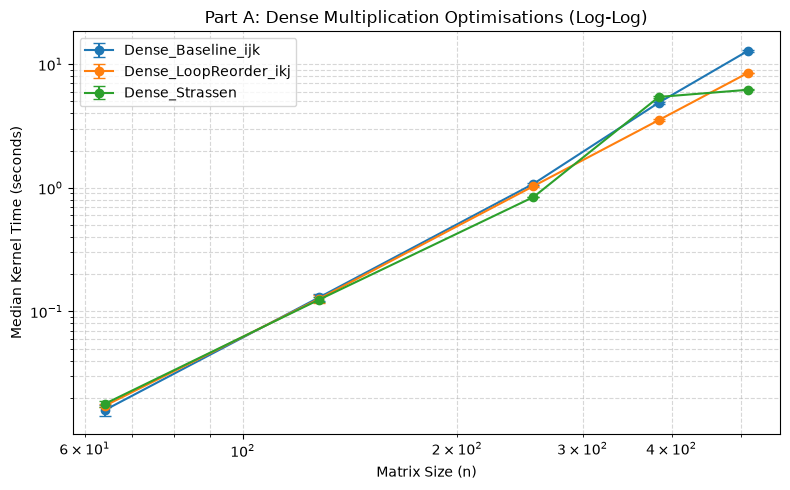

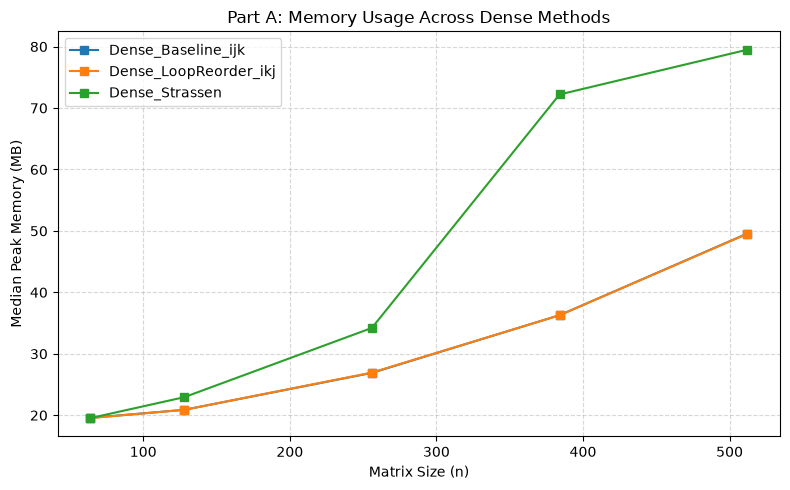

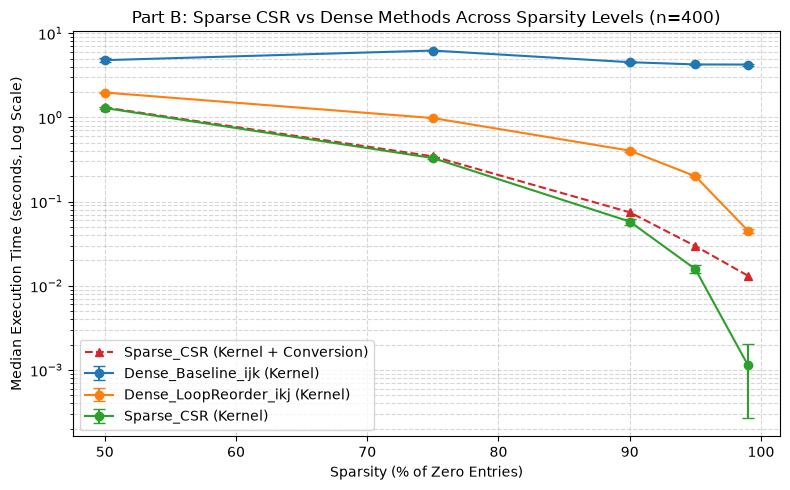

,method,representation,n,density,sparsity,repetitions,median_kernel_s,iqr_kernel_s,median_conv_s,median_total_s,iqr_total_s,median_memory_kb,nnz_a,nnz_b,nnz_c,checksum
0,Dense_Baseline_ijk,Dense_2D_List,200,0.01,0.99,5,0.498713,0.006464,0.000000,0.498713,0.006464,21720.0,371,398,734,1.876402e+02
1,Dense_Baseline_ijk,Dense_2D_List,200,0.05,0.95,5,0.493515,0.013896,0.000000,0.493515,0.013896,21760.0,1928,2019,15343,4.800413e+03
2,Dense_Baseline_ijk,Dense_2D_List,200,0.10,0.90,5,0.503560,0.010167,0.000000,0.503560,0.010167,22860.0,3920,4048,34805,2.003163e+04
3,Dense_Baseline_ijk,Dense_2D_List,200,0.25,0.75,5,0.489609,0.014333,0.000000,0.489609,0.014333,22368.0,9999,10047,39999,1.256591e+05
4,Dense_Baseline_ijk,Dense_2D_List,200,0.50,0.50,5,0.494809,0.018725,0.000000,0.494809,0.018725,23880.0,19888,19956,40000,4.949193e+05
5,Dense_Baseline_ijk,Dense_2D_List,400,0.01,0.99,5,4.245726,0.120967,0.000000,4.245726,0.120967,28548.0,1578,1618,6239,1.614394e+03
6,Dense_Baseline_ijk,Dense_2D_List,400,0.05,0.95,5,4.256625,0.024990,0.000000,4.256625,0.024990,28900.0,7884,8065,101120,4.007104e+04
7,Dense_Baseline_ijk,Dense_2D_List,400,0.10,0.90,5,4.527421,0.135340,0.000000,4.527421,0.135340,29424.0,15919,16070,157161,1.608815e+05
8,Dense_Baseline_ijk,Dense_2D_List,400,0.25,0.75,5,6.223860,0.139252,0.000000,6.223860,0.139252,31004.0,39896,40155,160000,1.000192e+06
9,Dense_Baseline_ijk,Dense_2D_List,400,0.50,0.50,5,4.787082,0.287833,0.000000,4.787082,0.287833,33480.0,79694,80215,160000,3.984138e+06


In [5]:
def iqr(series):
    return float(np.percentile(series, 75) - np.percentile(series, 25))

summary_a = df_raw_a.groupby(["method", "representation", "n", "density", "sparsity"], as_index=False).agg(
    repetitions=("kernel_time_s", "count"),
    median_kernel_s=("kernel_time_s", "median"),
    iqr_kernel_s=("kernel_time_s", iqr),
    median_memory_kb=("memory_kb", "median"),
    iqr_memory_kb=("memory_kb", iqr),
    checksum=("checksum", "first")
)
summary_a.to_csv("data/summary_part_a_dense.csv", index=False)

summary_b = df_raw_b.groupby(["method", "representation", "n", "density", "sparsity"], as_index=False).agg(
    repetitions=("kernel_time_s", "count"),
    median_kernel_s=("kernel_time_s", "median"),
    iqr_kernel_s=("kernel_time_s", iqr),
    median_conv_s=("conversion_time_s", "median"),
    median_total_s=("total_time_s", "median"),
    iqr_total_s=("total_time_s", iqr),
    median_memory_kb=("memory_kb", "median"),
    nnz_a=("nnz_a", "first"),
    nnz_b=("nnz_b", "first"),
    nnz_c=("nnz_c", "first"),
    checksum=("checksum", "first")
)
summary_b.to_csv("data/summary_part_b_sparse.csv", index=False)

plt.figure(figsize=(8, 5))
for m in summary_a["method"].unique():
    sub = summary_a[summary_a["method"] == m]
    plt.errorbar(sub["n"], sub["median_kernel_s"], yerr=sub["iqr_kernel_s"], marker="o", capsize=4, label=m)
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Matrix Size (n)")
plt.ylabel("Median Kernel Time (seconds)")
plt.title("Part A: Dense Multiplication Optimisations (Log-Log)")
plt.legend()
plt.grid(True, which="both", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.savefig("figures/part_a_dense_runtime.png", dpi=300)
plt.show()

plt.figure(figsize=(8, 5))
for m in summary_a["method"].unique():
    sub = summary_a[summary_a["method"] == m]
    plt.plot(sub["n"], sub["median_memory_kb"] / 1024.0, marker="s", label=m)
plt.xlabel("Matrix Size (n)")
plt.ylabel("Median Peak Memory (MB)")
plt.title("Part A: Memory Usage Across Dense Methods")
plt.legend()
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.savefig("figures/part_a_dense_memory.png", dpi=300)
plt.show()

n_focus = max(summary_b["n"].unique())
sub_b = summary_b[summary_b["n"] == n_focus]

plt.figure(figsize=(8, 5))
for m in sub_b["method"].unique():
    m_df = sub_b[sub_b["method"] == m].sort_values("sparsity")
    plt.errorbar(m_df["sparsity"] * 100.0, m_df["median_kernel_s"], yerr=m_df["iqr_kernel_s"], marker="o", capsize=4, label=f"{m} (Kernel)")
    if m == "Sparse_CSR":
        plt.plot(m_df["sparsity"] * 100.0, m_df["median_total_s"], marker="^", linestyle="--", label="Sparse_CSR (Kernel + Conversion)")
plt.yscale("log")
plt.xlabel("Sparsity (% of Zero Entries)")
plt.ylabel("Median Execution Time (seconds, Log Scale)")
plt.title(f"Part B: Sparse CSR vs Dense Methods Across Sparsity Levels (n={n_focus})")
plt.legend()
plt.grid(True, which="both", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.savefig("figures/part_b_sparse_vs_dense.png", dpi=300)
plt.show()

summary_b